In [200]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from IPython.display import clear_output

from assignment_2.carousel import Carousel

# **Section A** - _Training Data Pre-Processing and Analysis_

This section fixes the data for training and displays graphs on attrition based on age and job satisfaction.

## 1. Identifying and Handling Missing Values

In [201]:
CATEGORICAL_COLUMNS = ("Attrition", "BusinessTravel", "Department", "Gender", "JobRole", "OverTime")
ORDINAL_COLUMNS = ("EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction", "WorkLifeBalance")

def read_file(filename):
    """
    Opens a file and returns an array (two-dimensional if 2+ columns).
    Splits lines by comma and trims any leading or trailing whitespaces.
    """

    with open(filename) as file:
        lines = file.read().splitlines()

        # check if further processing for 2d arrays is required
        if "," in lines[0]:
            for k, v in enumerate(lines):
                split_line = v.split(",")

                for i, entry in enumerate(split_line):
                    entry = entry.strip()
                    try:
                        entry = float(entry)
                    except ValueError:
                        pass
                    split_line[i] = entry

                lines[k] = split_line

        return lines


def fix_data(data, headers):
    """
    Imputes missing numerical values and removes rows
    missing categorical values.
    """

    print(f"Initial number of rows: {len(data)}")

    averages = {}
    change = {}  # mark specific entries to change to avoid unnecessary comparisons

    remove = set()

    for index, header in enumerate(headers):

        categorical = header in CATEGORICAL_COLUMNS

        missing_values = 0

        running_total = 0
        included_entries = 0

        for row_index, row in enumerate(data):
            if row[index] == "":
                missing_values += 1

                if categorical:
                    remove.add(row_index)
                else:
                    if header not in change:
                        change[header] = []

                    change[header].append(row)

            elif not categorical:
                running_total += row[index]
                included_entries += 1

        if missing_values > 0:
            print(f"{header}: {missing_values} values missing ({'rows removed' if categorical else 'imputed'})")

            if not categorical:
                average = running_total / included_entries

                if header in ORDINAL_COLUMNS:
                    average = int(average)  # ordinal values cannot be decimal

                averages[header] = average

    removed = 0
    for index in range(len(data)):
        if index in remove:
            del data[index - removed]
            removed += 1
    print(f"Rows removed due to categorical missing values: {removed}")

    headers_to_change = list(change.keys())

    for header in headers_to_change:
        average = averages[header]
        index = headers.index(header)

        for row in change[header]:
            row[index] = average

    print(f"Remaining number of rows: {len(data)}")

    # verify everything has been imputed/removed
    for row in data:
        assert "" not in row, "Value missing from fixed data!"

    print("\nConfirmed: No missing values remain in the dataset.")


data = read_file("train.csv")
headers = data.pop(0)

fix_data(data, headers)


Initial number of rows: 1029
Age: 64 values missing (imputed)
Attrition: 53 values missing (rows removed)
BusinessTravel: 44 values missing (rows removed)
Department: 51 values missing (rows removed)
DistanceFromHome: 53 values missing (imputed)
EnvironmentSatisfaction: 52 values missing (imputed)
Gender: 49 values missing (rows removed)
JobInvolvement: 67 values missing (imputed)
JobRole: 50 values missing (rows removed)
JobSatisfaction: 47 values missing (imputed)
NumCompaniesWorked: 55 values missing (imputed)
MonthlyIncome: 65 values missing (imputed)
OverTime: 36 values missing (rows removed)
PercentSalaryHike: 54 values missing (imputed)
WorkLifeBalance: 59 values missing (imputed)
YearsAtCompany: 34 values missing (imputed)
YearsInCurrentRole: 39 values missing (imputed)
YearsSinceLastPromotion: 52 values missing (imputed)
Rows removed due to categorical missing values: 259
Remaining number of rows: 770

Confirmed: No missing values remain in the dataset.


## 2. Analyzing Attrition Distribution by Age (Bar Chart)

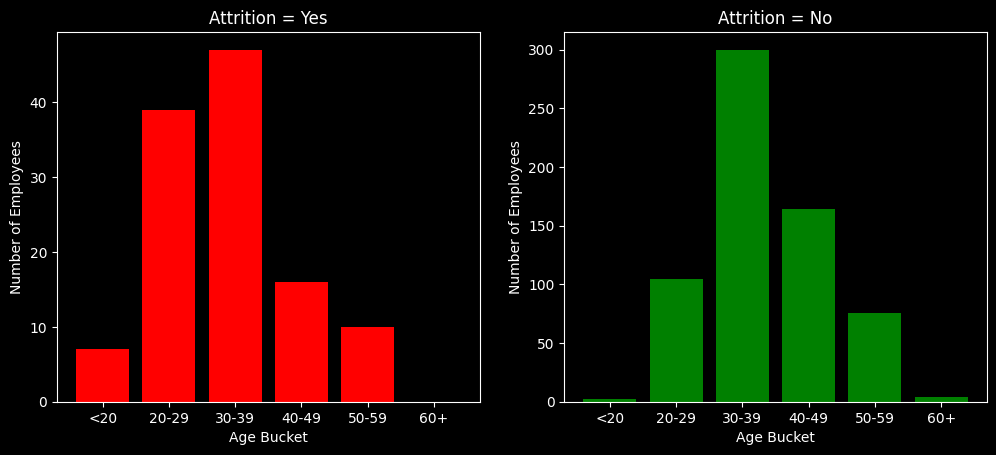

In [202]:
buckets = ("<20", "20-29", "30-39", "40-49", "50-59", "60+")
fig, ax = plt.subplots(1, 2)
fig.set_figwidth(12)  # set spacing so graphs aren't squished

attrition_index = headers.index("Attrition")
age_index = headers.index("Age")

attrition_groups = [[], []]


for entry in data:
    if entry[attrition_index] == "Yes":
        attrition_groups[0].append(entry)
    else:
        attrition_groups[1].append(entry)


for key, value in enumerate(("Yes", "No")):
    ax[key].set_title(f"Attrition = {value}")
    ax[key].set(ylabel="Number of Employees", xlabel="Age Bucket")

    group = attrition_groups[key].copy()

    # setup bucket bounds
    lower_bound = 0
    upper_bound = 20

    bucket_counts = []  # the # of entries in each bucket

    for i in range(5):  # repeat for every bucket that has x-y range

        running_total = 0

        for j in range(len(group) -1, -1, -1):

            entry = group[j]

            if lower_bound <= entry[age_index] < upper_bound:
                running_total += 1
                del group[j]

        bucket_counts.append(running_total)

        lower_bound = upper_bound
        upper_bound += 10

    bucket_counts.append(len(group))  # all remaining entries will be 60+ years of age

    ax[key].bar(buckets, bucket_counts, color=("Red", "Green")[key])


## 3. Analyzing Attrition Among Employees based on Job Satisfaction (Pie Chart)

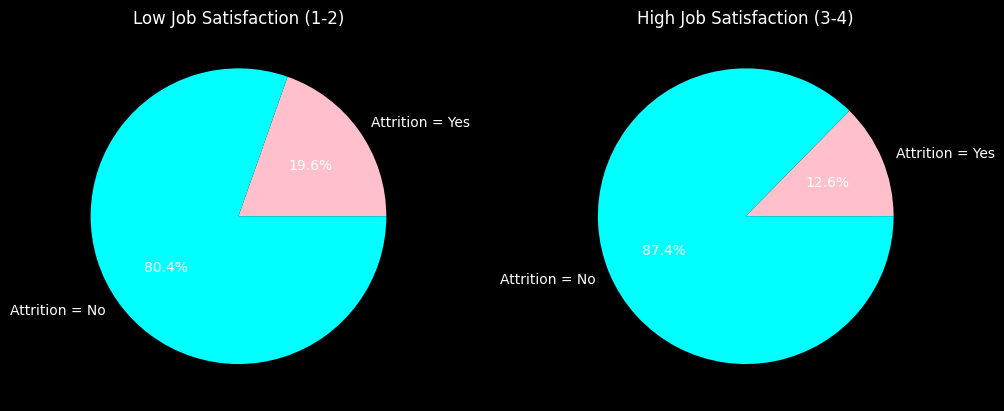

In [203]:
satisfaction_index = headers.index("JobSatisfaction")

satisfactions = ("Low Job Satisfaction (1-2)", "High Job Satisfaction (3-4)")
satisfaction_groups = [[], []]

fig, ax = plt.subplots(1, 2)
fig.set_figwidth(12)

for entry in data:
    if entry[satisfaction_index] <= 2:
        satisfaction_groups[0].append(entry)
    else:
        satisfaction_groups[1].append(entry)

for key, value in enumerate(satisfactions):
    plot = ax[key]
    plot.set_title(value)

    group = satisfaction_groups[key]

    attrition = [0, 0]  # 0th yes, 1st no

    for entry in group:
        attrition[0 if entry[attrition_index] == "Yes" else 1] += 1

    plot.pie(attrition, labels=("Attrition = Yes", "Attrition = No"), colors=("Pink", "Aqua"), autopct='%1.1f%%')



## 4. Checking for Class Imbalance in the Training Data

In [204]:
print(f"Number of employees who quit (Attrition=Yes): {len(attrition_groups[0])}")  # use sorted lists from earlier (1.2)
print(f"Number of employees who quit (Attrition=No): {len(attrition_groups[1])}")

Number of employees who quit (Attrition=Yes): 119
Number of employees who quit (Attrition=No): 651


# **Section B** - _Building the Decision Tree Classifier_

This section does final preparations on the data for training (such as scaling the data), builds the decision tree, and tests it.



## 1. Preparing the Data for Training

In [205]:
scaler = StandardScaler()

def scale_data(data, headers, is_test=False):
    cleaned_data = []

    non_categorical_headers = []

    for header in headers:
        if not header in CATEGORICAL_COLUMNS:
            non_categorical_headers.append(header)

    for entry in data:
        new_entry = []

        for key, value in enumerate(headers):
            if value in non_categorical_headers:
                new_entry.append(entry[key])

        cleaned_data.append(new_entry)

    if is_test:  # if it is the test data, use transform NOT fit_transform.
        scaled_data = scaler.transform(cleaned_data)
    else:
        scaled_data = scaler.fit_transform(cleaned_data)

    return scaled_data

scaled_data = scale_data(data, headers)

## 2. Building the Decision Tree Classifier
### 2.1 Training the Model

In [206]:
x_train, y_train = [], []

for index in range(len(data)):
    x_train.append(scaled_data[index])

    attrition = data[index][attrition_index]
    y_train.append(1 if attrition == "Yes" else 0)

clf = DecisionTreeClassifier(random_state=42)
clf.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

### 2.2 Evaluating the Model

In [207]:
test_data = read_file("test.csv")
test_headers = test_data.pop(0)

fix_data(test_data, test_headers)
scaled_test_data = scale_data(test_data, test_headers, True)

x_test, y_test = [], []

for index in range(len(test_data)):
    x_test.append(scaled_test_data[index])

    attrition = test_data[index][attrition_index]
    y_test.append(1 if attrition == "Yes" else 0)

y_pred = clf.predict(x_test)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 2))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Initial number of rows: 441
Rows removed due to categorical missing values: 0
Remaining number of rows: 441

Confirmed: No missing values remain in the dataset.
Test Accuracy: 0.77

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.87      0.86       365
           1       0.31      0.28      0.29        76

    accuracy                           0.77       441
   macro avg       0.58      0.58      0.58       441
weighted avg       0.76      0.77      0.77       441


Confusion Matrix:
 [[319  46]
 [ 55  21]]


# **Section 3** - _Deployment of the Predictor_

This section uses the decision tree classifier built in Section B to predict the attrition of new employees. The predicted data can then be viewed in a carousel format.

## 1. Prediction

In [208]:
def predict_new_employees():
    """
    Loads new employee info, predicts their attrition, and returns
    their info alongside prediction.
    """
    data = read_file("NewEmployees.csv")
    headers = data.pop(0)
    headers.pop(0)

    result = {}
    employee_names = []

    data_to_scale = []
    for entry in data:
        employee_names.append(entry.pop(0))  # remove column with name
        data_to_scale.append(entry)

    scaled_data = scale_data(data_to_scale, headers, True)

    print(f"Processed {len(data)} employees")

    predictions = clf.predict(scaled_data)

    index = 0
    for prediction in predictions:
        data[index].append("Yes" if prediction == 1 else "No")
        result[employee_names[index]] = data[index]

        index += 1

    print(f"Generated {len(predictions)} predictions")

    return result


predicted_data = predict_new_employees()

Processed 9 employees
Generated 9 predictions


# 2. Circular Doubly-Linked List
_See `carousel.py`_

## 3. Interface

In [209]:
line_seperator = "-" * 50

def display_employee(name, entry, headers):
    """
    Display employee info given their name, statistics, and
    the headers for said statistics.
    """
    info = entry[:-1]
    attrition = entry[-1]

    print(line_seperator)
    print(f"Employee Name: {name}")
    print(line_seperator)

    for header in headers:
        data = info.pop(0)
        print(f"  {header}: {data}")

    print(line_seperator)
    print(f"Prediction (Likely to Quit): {attrition}")

    recommend = "Flag for Retention"
    if attrition == "No":
        recommend = "No Action Needed"

    print(f"Recommend: {recommend}")
    print(line_seperator)


def display_flagged_employees(flagged, data):
    """
    Displays flagged employees
    """
    print(line_seperator)
    print("FLAGGED EMPLOYEES FOR RETENTION PLANNING")
    print(line_seperator)

    for key, value in enumerate(flagged):
        print(f"{key + 1}. {value} - Prediction: {data[value][-1]}")

    print(line_seperator)



def get_integer(prompt, min, max):
    """
    Gets an integer from the user between (inclusive) min and max.
    """

    num = min - 1
    while not (min <= num <= max):
        try:
            num = int(input(prompt))
        except ValueError:
            pass

    return num


carousel = Carousel()
flagged_employees = []

for entry in predicted_data:
    carousel.add(entry)  # add employee name to carousel

repeat = True
main_view = True
while repeat:
    clear_output(wait=True)

    current_employee = carousel.getCurrentData()
    current_employee_data = predicted_data[current_employee]

    if main_view:
        display_employee(current_employee, current_employee_data, headers)
    else:
        display_flagged_employees(flagged_employees, predicted_data)

    print("\nEnter 1 for Next; 2 for Previous; 3 to Flag; 4 to Switch View; 0 to Quit")
    choice = get_integer("Enter choice: (Press 'Enter' to confirm or 'Escape' to cancel)", 0, 4)

    if choice == 1:
        carousel.moveNext()

    elif choice == 2:
        carousel.movePrevious()

    elif choice == 3:
        if current_employee in flagged_employees:
            flagged_employees.remove(current_employee)
        else:
            flagged_employees.append(current_employee)

    elif choice == 4:
        main_view = not main_view

    elif choice == 0:
        repeat = False


--------------------------------------------------
Employee Name: Christopher Lee
--------------------------------------------------
  Age: 35.0
  Attrition: No
  BusinessTravel: Travel_Rarely
  Department: Research & Development
  DistanceFromHome: 4.0
  EnvironmentSatisfaction: 3.0
  Gender: Male
  JobInvolvement: 3.0
  JobRole: Research Scientist
  JobSatisfaction: 3.0
  NumCompaniesWorked: 2.0
  MonthlyIncome: 6800.0
  OverTime: No
  PercentSalaryHike: 16.0
  WorkLifeBalance: 3.0
  YearsAtCompany: 6.0
  YearsInCurrentRole: 4.0
  YearsSinceLastPromotion: 2.0
--------------------------------------------------
Prediction (Likely to Quit): No
Recommend: No Action Needed
--------------------------------------------------
Enter 1 for Next; 2 for Previous; 3 to Flag; 4 to Switch View; 0 to Quit
